# Food purchasing and educational attainment

Exploring associations between grocery purchasing patterns and GCSE and English Baccalaureate (EBacc) results across London boroughs.

## Research questions

- How does educational attainment vary across London boroughs?
- Are healthier food purchasing patterns associated with higher
  educational attainment?
- How do individual food categories and nutritional indicators
  correlate with GCSE and EBacc results?

In [1]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

## Data sources
- [Tesco Grocery 1.0](https://www.nature.com/articles/s41597-020-0397-7):
  Annual grocery purchasing and nutritional statistics across London
  boroughs for 2015.

- [GCSE Results 2014–2015](https://www.gov.uk/government/statistics/revised-gcse-and-equivalent-results-in-england-2014-to-2015):
  Educational attainment statistics published by the Department for
  Education.

The datasets are matched using local authority codes.

In [2]:
# Load annual grocery purchasing data and educational attainment data
annual = pd.read_csv("data/year_borough_grocery.csv")
education = pd.read_excel("data/education.xlsx")

# Merge datasets using local authority identifiers
combined_df = annual.merge(
    education,
    left_on="area_id",
    right_on="Code",
    validate="one_to_one"
)
# combined_df.to_excel("data/combined data.xlsx", index=False)
# or load data/combined data.xlsx directly

## Educational attainment across London boroughs

In [3]:
# Educational attainment measures used throughout the analysis
GCSE = "Percentage of pupils achieving 5+ A*-C grades inc. English and mathematics GCSEs"
EBACC = "Percentage of pupils  Achieving the English Baccalaureate"

GCSE_ALL = "Percentage of pupils achieving 5+ A*-C grades"
EBACC_ENTRY = "Percentage of pupils  Entering the English Baccalaureate"

English Baccalaureate

EBacc entry and achievement rates are compared to explore differences in participation and attainment across boroughs.

Entering EBacc     48.22%
Achieving EBacc    32.12%
dtype: object


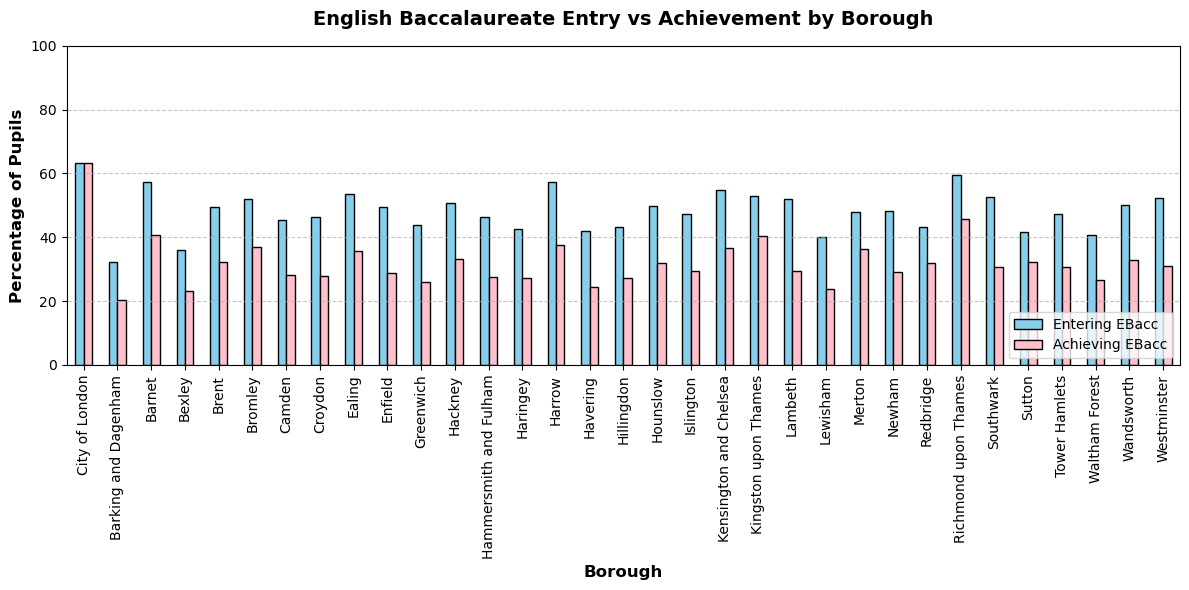

In [4]:
# Report equally weighted borough averages, rather than pupil-weighted London averages.
distribution = combined_df.set_index("local authority name")[[EBACC_ENTRY, EBACC]]
distribution.columns = ['Entering EBacc', 'Achieving EBacc']
print(distribution.mean().round(2).astype(str) + "%")

distribution.plot(kind="bar", figsize=(12, 6), color=["skyblue", "pink"], edgecolor="black")
plt.xlabel("Borough", fontsize=12, fontweight="bold")
plt.ylabel("Percentage of Pupils", fontsize=12, fontweight="bold")
plt.title('English Baccalaureate Entry vs Achievement by Borough', fontsize=14, fontweight="bold", pad=15)
plt.ylim(0, 100)
plt.xticks(rotation=90)
plt.legend(loc="lower right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [5]:
# EBacc achievement rates are lower than entry rates, with both
# measures varying across boroughs. These geographical differences
# provide a basis for investigating potential associations with
# food purchasing patterns.

GCSE attainment

Overall GCSE attainment is compared with attainment including English and Mathematics. The latter measure is used in the GCSE correlation analysis.

5+ A*-C grades                       72.13%
5+ A*-C including English & Maths    61.91%
dtype: object


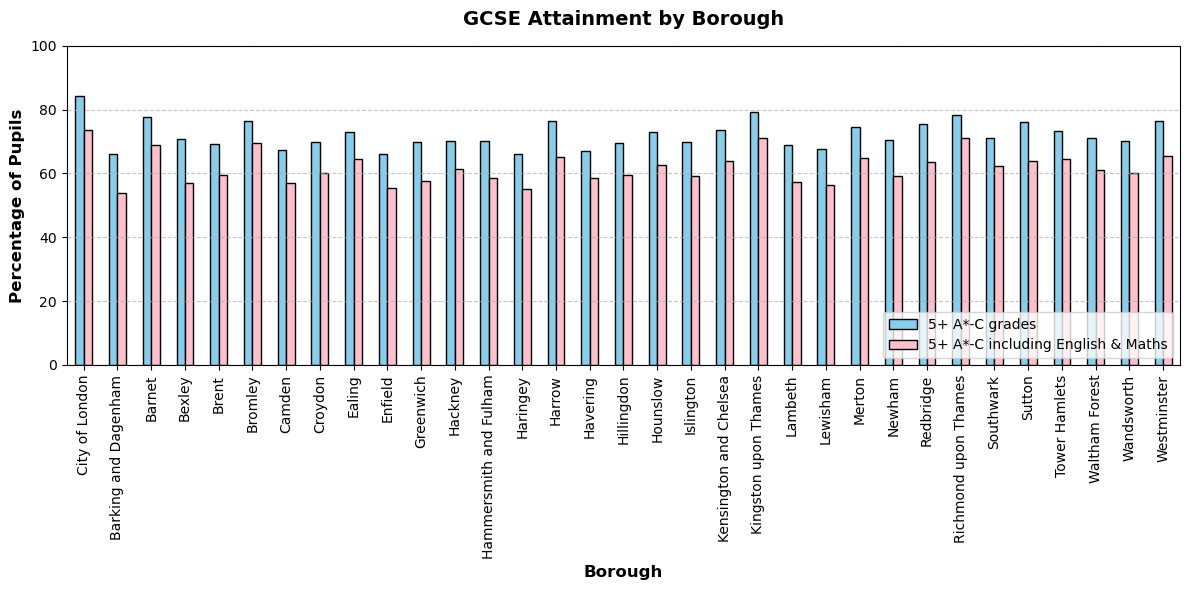

In [6]:
# Report equally weighted borough averages, rather than pupil-weighted London averages.
distribution = combined_df.set_index("local authority name")[[GCSE_ALL, GCSE]]
distribution.columns = ['5+ A*-C grades', '5+ A*-C including English & Maths']
print(distribution.mean().round(2).astype(str) + "%")

distribution.plot(kind="bar", figsize=(12, 6), color=["skyblue", "pink"], edgecolor="black")
plt.xlabel("Borough", fontsize=12, fontweight="bold")
plt.ylabel("Percentage of Pupils", fontsize=12, fontweight="bold")
plt.title('GCSE Attainment by Borough', fontsize=14, fontweight="bold", pad=15)
plt.ylim(0, 100)
plt.xticks(rotation=90)
plt.legend(loc="lower right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

GCSE attainment varies across London boroughs. The percentage
of pupils achieving five or more A*–C grades including English
and Mathematics is lower than overall attainment.

The English and Mathematics measure is retained consistently
throughout the GCSE correlation analysis.

## Correlation Analysis

Pearson's correlation coefficient is used to investigate the strength
and direction of linear relationships between grocery purchasing
indicators and educational attainment.

In [7]:
# A positive correlation indicates that higher values of a purchasing
# indicator are associated with higher attainment, while a negative
# correlation indicates the opposite.

# Scatter plots with fitted regression lines are used to visualise
# these relationships.

In [8]:
def plot_correlation(column, label, attainment, outcome, color=None):
    """Plot a purchasing indicator against an attainment measure and report Pearson r."""
    # Use the same complete observations for the plot and correlation.
    data = combined_df[[column, attainment]].dropna()
    correlation = data[column].corr(data[attainment])
    plt.figure(figsize=(8, 6))
    sns.regplot(data=data, x=column, y=attainment, scatter_kws={"alpha": 0.5}, color=color)
    plt.xlabel(label, fontsize=12, fontweight="bold")
    plt.ylabel(f"{outcome} (%)", fontsize=12, fontweight="bold")
    plt.title(f"{label} vs {outcome}\nPearson r = {correlation:.3f}", fontsize=14, fontweight="bold", pad=15)
    plt.tight_layout()
    plt.show()

GCSE attainment

GCSE attainment refers to the percentage of pupils achieving five or more A*–C grades, including English and Mathematics. Seven food and nutritional indicators are examined.

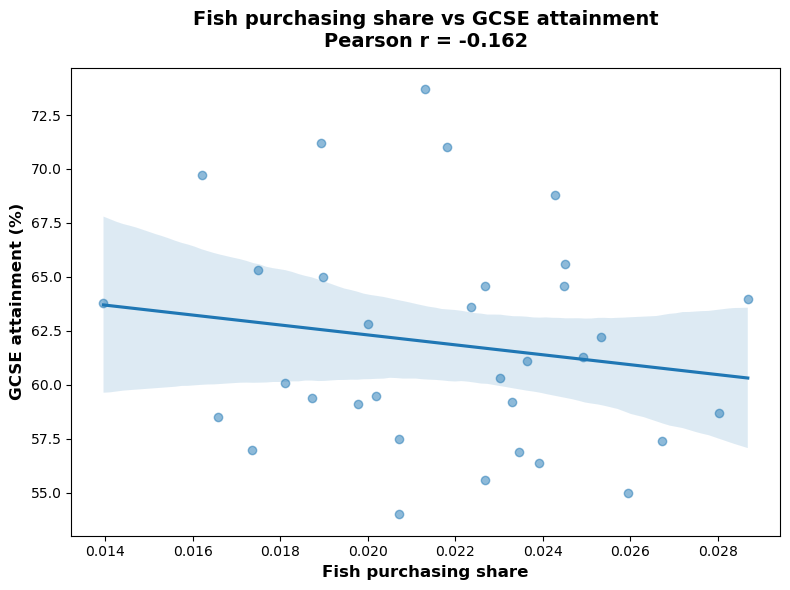

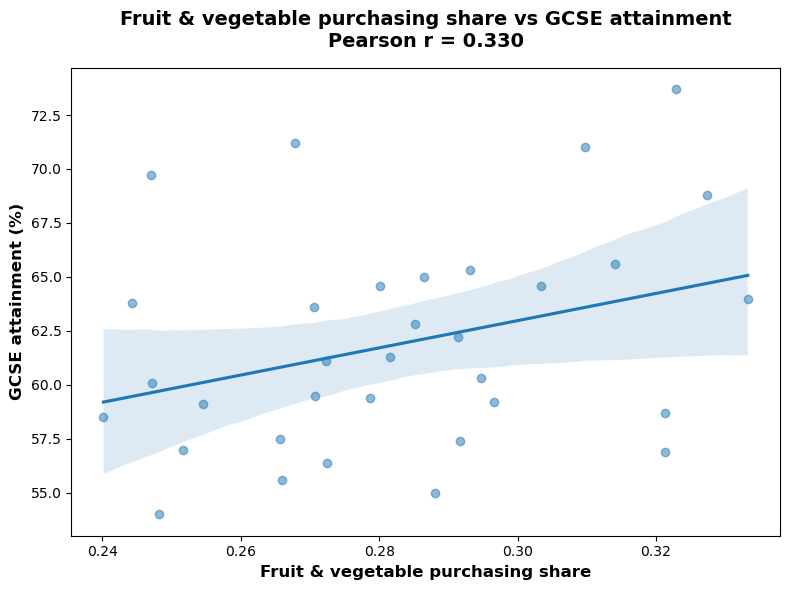

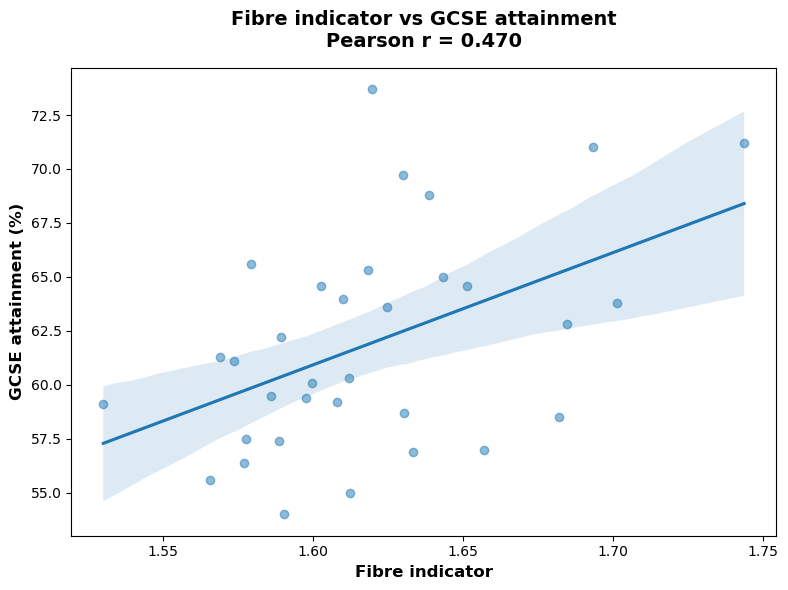

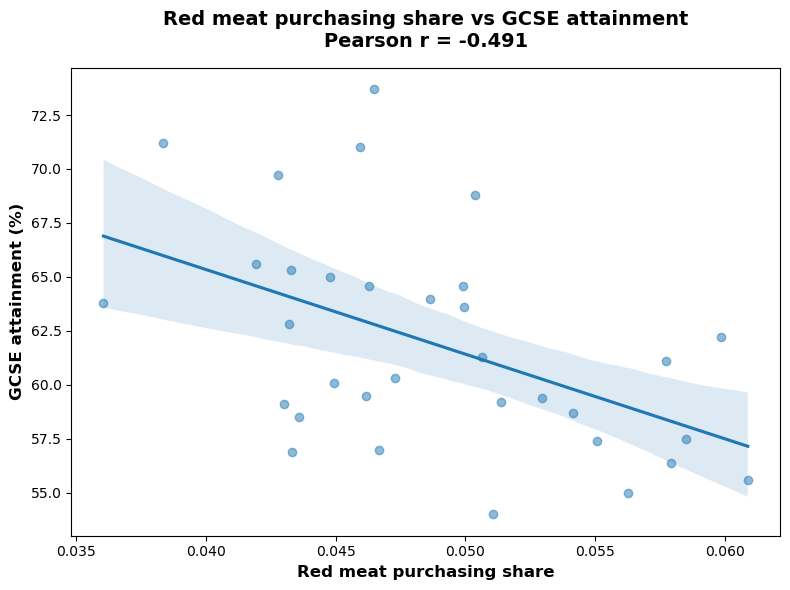

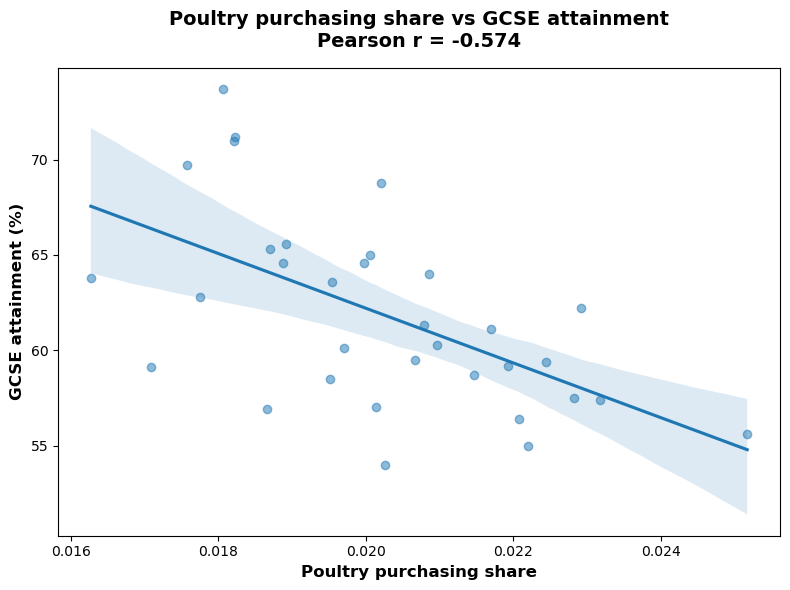

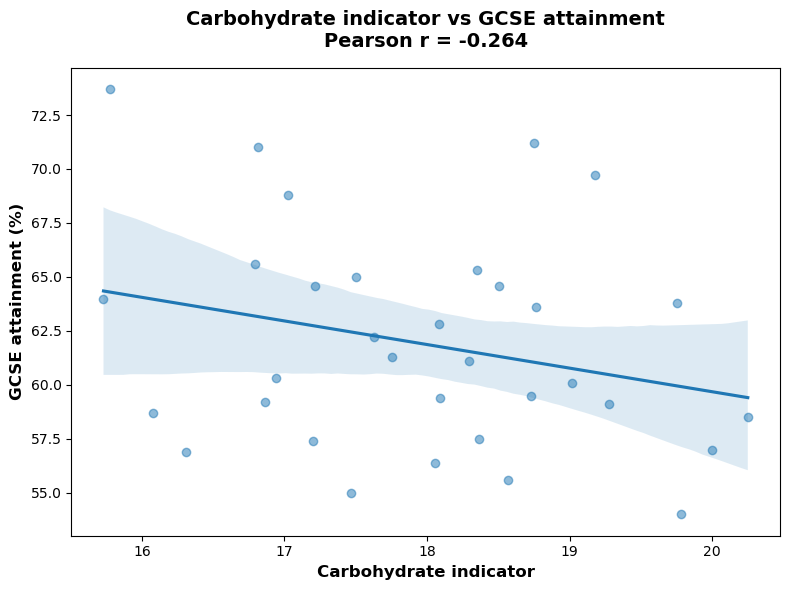

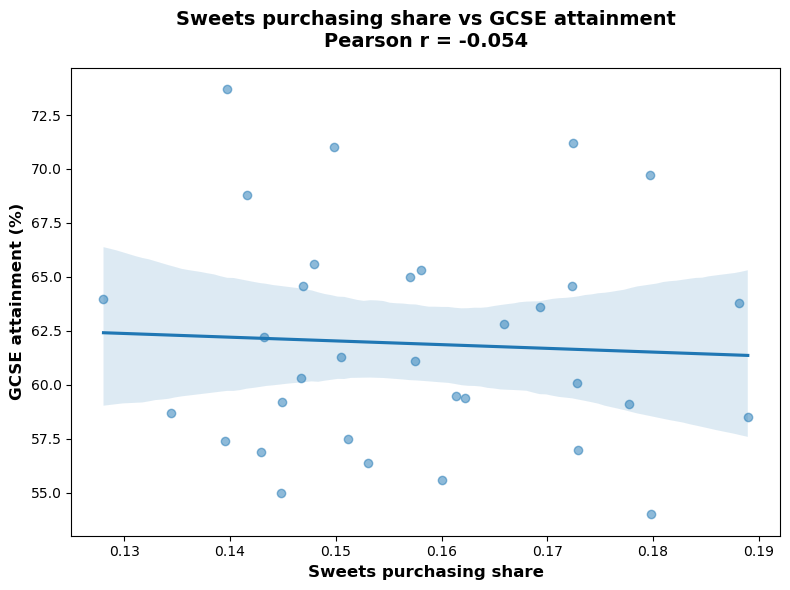

In [9]:
plot_correlation("f_fish", "Fish purchasing share", GCSE, "GCSE attainment")

plot_correlation("f_fruit_veg", "Fruit & vegetable purchasing share", GCSE, "GCSE attainment")

plot_correlation("fibre", "Fibre indicator", GCSE, "GCSE attainment")

plot_correlation("f_meat_red", "Red meat purchasing share", GCSE, "GCSE attainment")

plot_correlation("f_poultry", "Poultry purchasing share", GCSE, "GCSE attainment")

plot_correlation("carb", "Carbohydrate indicator", GCSE, "GCSE attainment")

plot_correlation("f_sweets", "Sweets purchasing share", GCSE, "GCSE attainment")

Observations

Fibre (r = 0.470) and fruit and vegetable purchasing shares (r = 0.330) show positive correlations. Poultry and red meat show negative correlations of -0.574 and -0.491, respectively. Fish and sweets show weaker linear associations.

EBacc attainment

Fruit and vegetable purchasing shares, sugar and energy indicators are compared with the percentage of pupils achieving the English Baccalaureate.

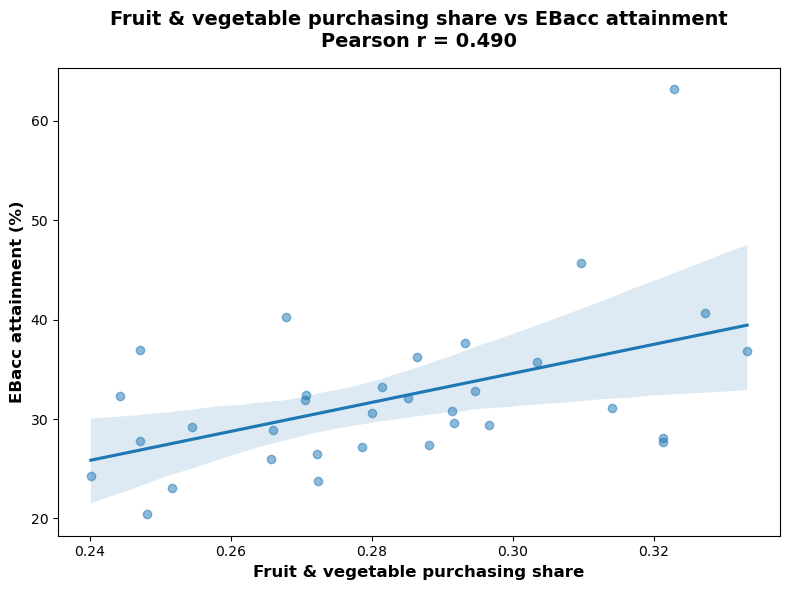

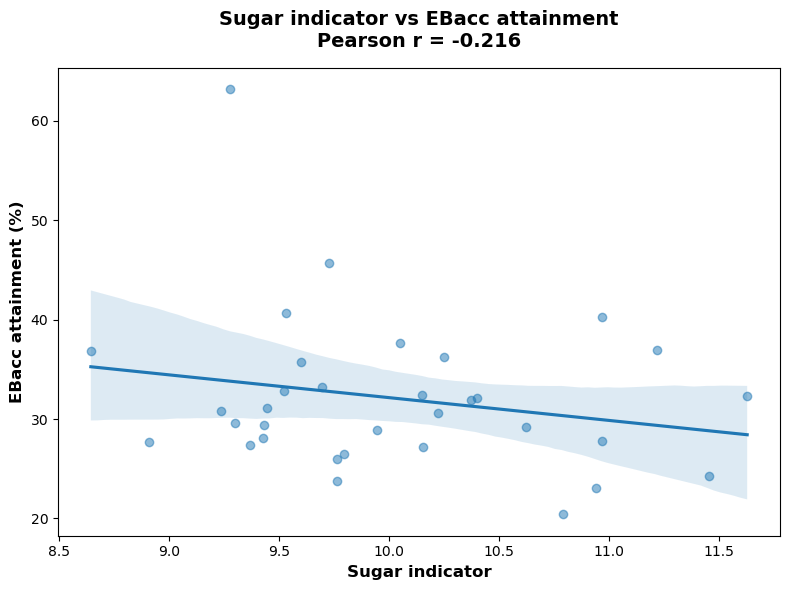

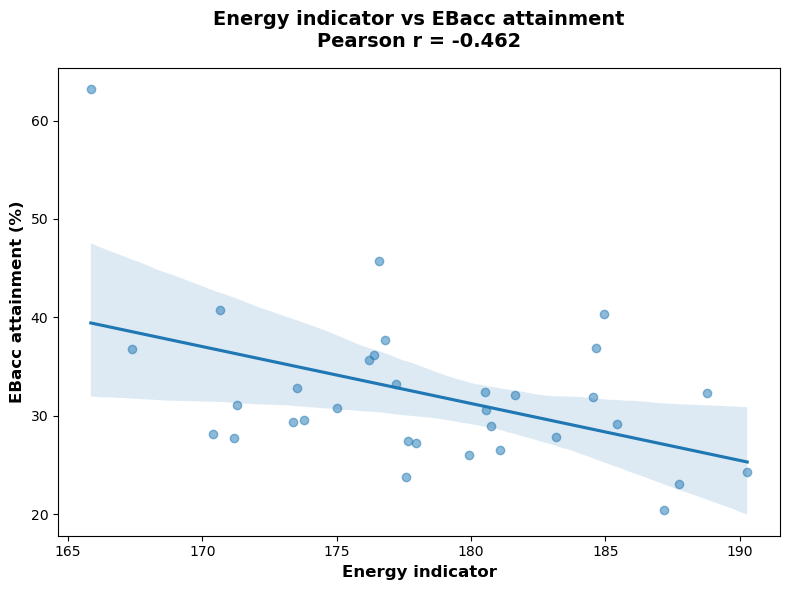

In [10]:
plot_correlation(
    "f_fruit_veg",
    "Fruit & vegetable purchasing share",
    EBACC,
    "EBacc attainment"
)

plot_correlation(
    "sugar",
    "Sugar indicator",
    EBACC,
    "EBacc attainment"
)

plot_correlation(
    "energy_tot",
    "Energy indicator",
    EBACC,
    "EBacc attainment"
)

Observations

Fruit and vegetable purchasing shares show a positive correlation (r = 0.490), while sugar (r = -0.216) and energy (r = -0.462) show negative correlations.

### Summary of correlations

The heatmap compares the Pearson correlation coefficients
between grocery purchasing indicators and GCSE and EBacc
attainment, highlighting similarities and differences
across the two educational outcomes.

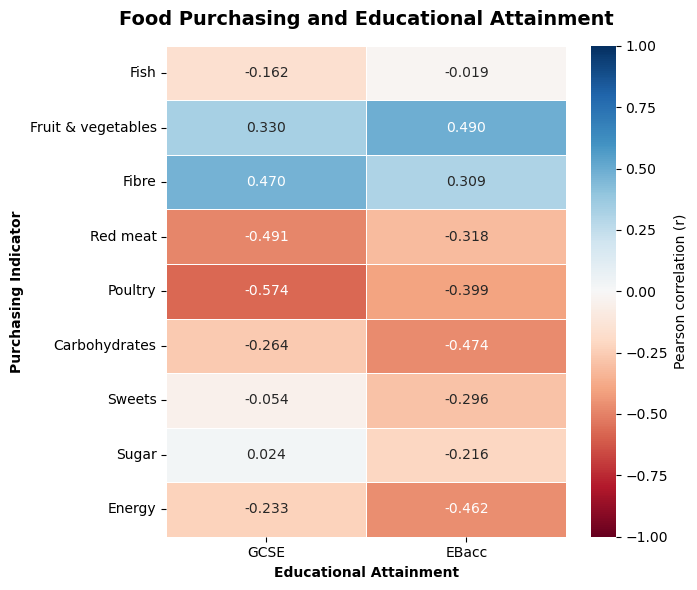

In [11]:
# Food categories and nutritional indicators
indicators = {
    "f_fish": "Fish",
    "f_fruit_veg": "Fruit & vegetables",
    "fibre": "Fibre",
    "f_meat_red": "Red meat",
    "f_poultry": "Poultry",
    "carb": "Carbohydrates",
    "f_sweets": "Sweets",
    "sugar": "Sugar",
    "energy_tot": "Energy"
}

# Compare correlations across both attainment measures
correlation_summary = pd.DataFrame({
    "GCSE": combined_df[list(indicators)].corrwith(combined_df[GCSE]),
    "EBacc": combined_df[list(indicators)].corrwith(combined_df[EBACC])
}).rename(index=indicators)

plt.figure(figsize=(7, 6))

sns.heatmap(
    correlation_summary,
    annot=True,
    fmt=".3f",
    cmap="RdBu",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson correlation (r)"}
)

plt.title(
    "Food Purchasing and Educational Attainment",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Educational Attainment", fontweight="bold")
plt.ylabel("Purchasing Indicator", fontweight="bold")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#### Observations

- Fruit and vegetables and fibre show positive correlations
  with both educational attainment measures.
- Poultry shows the strongest negative correlation with
  GCSE attainment (r = -0.574).
- Carbohydrates show the strongest negative correlation
  with EBacc attainment (r = -0.474), closely followed
  by energy (r = -0.462).
- Sugar shows almost no linear relationship with GCSE
  attainment but a weak negative correlation with EBacc.
- Fish shows weak or negligible correlations with both
  educational outcomes.

The differences suggest that the observed relationships
vary depending on the educational attainment measure used.

## Conclusion

Fruit and vegetable purchasing shares and fibre show positive
associations with both GCSE and EBacc attainment. In contrast,
red meat, poultry and carbohydrate indicators show negative
associations with both educational outcomes.

The strength of these relationships varies depending on the
attainment measure used, highlighting the importance of
considering multiple educational outcomes.

### Limitations

- Grocery purchases do not necessarily reflect actual dietary intake.
- Tesco Clubcard users may not represent the wider population.
- Socioeconomic factors, household income and school quality
  may influence the observed relationships.
- Borough-level associations cannot be generalised to individual pupils.

Further analysis incorporating socioeconomic and demographic
variables could help determine whether these associations persist
after accounting for potential confounding factors.

The findings are exploratory and do not establish a causal
relationship between diet and educational attainment.